# VISST Applied Linear Algebra

## Lab: Least Squares Linear Regression

Load a house price dataset:

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LinearRegression

np.set_printoptions(precision=3, suppress=True)

df = fetch_openml("house_prices", as_frame=True).frame
y = df["SalePrice"].to_numpy() / 1000  # price in thousands of dollars

Here are the first 5 rows of the dataset. 

In [3]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Total number of houses $n$:

In [6]:
len(df)

1460

## Part 1: One feature

Our one feature is the above-ground floor area `GrLivArea`, in square feet.

In [5]:
x = df["GrLivArea"].to_numpy()
x.shape, y.shape

((1460,), (1460,))

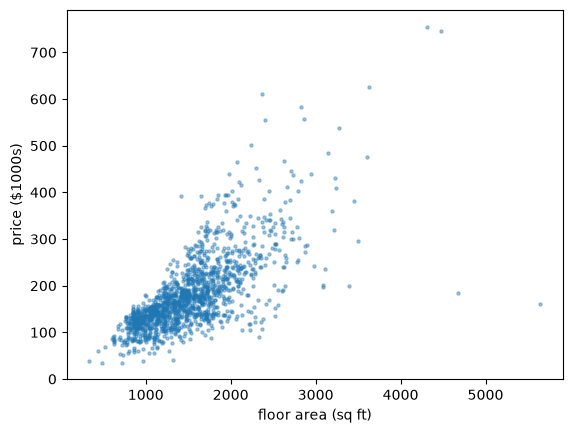

In [8]:
grid = np.linspace(0, x.max(), 100)
plt.scatter(x, y, s=5, alpha=0.4)
plt.xlabel("floor area (sq ft)")
plt.ylabel("price ($1000s)");

**(a)** Compute the slope `w` of the best fit line through the origin, using the formula from the worksheet. 

In [ ]:
w = 0  # TODO
w

**(b)** Run the cell below to plot your line. Does it look like a good fit?

In [ ]:
grid = np.linspace(0, x.max(), 100)
plt.scatter(x, y, s=5, alpha=0.4)
plt.plot(grid, w * grid, "r", label=f"$\\hat{{y}} = {w:.3f}x$")
plt.xlabel("floor area (sq ft)")
plt.ylabel("price ($1000s)")
plt.legend();

**(c)** scikit-learn is an extremely popular python library for machine learning. Let's check against scikit-learn's `LinearRegression`. We set `fit_intercept=False` so it also goes through the origin. Your `w` should match.

In [ ]:
lr = LinearRegression(fit_intercept=False).fit(x[:, None], y)
lr.coef_

**(d)** In words, what does your value of `w` mean? Include units. Using your model, what's the predicted price of a 2000 sq ft house?

_Your answer here._

## Part 2: Many features

Now each house is a row of `X` and each feature is a column. We'll use 7 features: floor area, number of bedrooms, number of full bathrooms, number of half bathrooms, number of garage parking spots, build quality score, and year build. 

In [10]:
features = ["GrLivArea", "BedroomAbvGr", "FullBath", "HalfBath", "GarageCars", "OverallQual", "YearBuilt"]
X = df[features].to_numpy()

Print the shape of the matrix $X$, which is $n$-by-$d$:

In [11]:
X.shape

(1460, 7)

Looking at some of the data in $X$:

In [12]:
X

array([[1710,    3,    2, ...,    2,    7, 2003],
       [1262,    3,    2, ...,    2,    6, 1976],
       [1786,    3,    2, ...,    2,    7, 2001],
       ...,
       [2340,    4,    2, ...,    1,    7, 1941],
       [1078,    2,    1, ...,    1,    5, 1950],
       [1256,    3,    1, ...,    1,    5, 1965]])

**(a)** Compute the weight vector `w` with the normal equations. (Use `np.linalg.solve` to solve a linear system.)

In [ ]:
w = 0  # TODO
pd.Series(w, index=features)

**(b)** Compare with scikit-learn. They should match.

In [ ]:
lr = LinearRegression(fit_intercept=False).fit(X, y)
pd.DataFrame({"ours": w, "sklearn": lr.coef_}, index=features)

**(c)** Now compute the weights again, but this time using `np.linalg.inv` to compute $(X^TX)^{-1}$ and then multiplying. Compare with your answer from `solve`.

In [ ]:
w_inv = 0  # TODO
pd.DataFrame({"solve": w, "inv": w_inv}, index=features)

You should get basically the same answer here. But in general, **always use `solve`** rather than computing an inverse: it's faster, and it's more accurate when $X^TX$ is close to non-invertible.

**(d)** Interpret the weights:
- Which weights are positive and which are negative? Do the signs make sense?
- The `GrLivArea` weight is different than in Part 1. Why?
- Look at the `BedroomAbvGr` weight. Does it mean adding a bedroom to a house lowers its price? (Hint: what's being held fixed?)

_Your answer here._

**(e)** Can you compare the magnitudes of the weights directly to decide which feature is "most important"? Think about units.

_Your answer here._

## Part 3: Adding a $y$-intercept

The code below makes `X_aug` by adding a column of 1's as the first column of `X`. Take a look at it, and check its shape: $d$ is now 8 instead of 7.

In [ ]:
X_aug = np.column_stack([np.ones(len(X)), X])
X_aug

In [ ]:
X_aug.shape

**(a)** Fit `w` exactly like before, but using `X_aug` instead of `X`.

In [ ]:
w = 0  # TODO
pd.Series(w, index=["intercept"] + features)

**(b)** Compare with scikit-learn, this time with its default `fit_intercept=True`. Note that scikit-learn stores the intercept separately in `intercept_`.

In [ ]:
lr = LinearRegression().fit(X, y)
pd.DataFrame({"ours": w, "sklearn": np.r_[lr.intercept_, lr.coef_]}, index=["intercept"] + features)

**(c)** Which weight changed the most after adding the intercept? Why do you think that feature in particular was affected? (Hint: what were the values of that feature for every house?)

_Your answer here._